# **Problem Statement**


---

#### **Business Context**  
Understanding customer personality and behavior is pivotal for businesses to enhance customer satisfaction and increase revenue. Segmentation based on a customer's personality, demographics, and purchasing behavior allows companies to create tailored marketing campaigns, improve customer retention, and optimize product offerings.  

A leading retail company with a rapidly growing customer base seeks to gain deeper insights into their customers' profiles. The company recognizes that understanding customer personalities, lifestyles, and purchasing habits can unlock significant opportunities for personalizing marketing strategies and creating loyalty programs. These insights can help address critical business challenges, such as improving the effectiveness of marketing campaigns, identifying high-value customer groups, and fostering long-term relationships with customers.  

With the competition intensifying in the retail space, moving away from generic strategies to more targeted and personalized approaches is essential for sustaining a competitive edge.  

---

#### **Objective**  
In an effort to optimize marketing efficiency and enhance customer experience, the company has embarked on a mission to identify distinct customer segments. By understanding the characteristics, preferences, and behaviors of each group, the company aims to:  
1. Develop personalized marketing campaigns to increase conversion rates.  
2. Create effective retention strategies for high-value customers.  
3. Optimize resource allocation, such as inventory management, pricing strategies, and store layouts.  

As a data scientist tasked with this project, your responsibility is to analyze the given customer data, apply machine learning techniques to segment the customer base, and provide actionable insights into the characteristics of each segment.  

---

#### **Data Dictionary**  
The dataset includes historical data on customer demographics, personality traits, and purchasing behaviors. Key attributes are:  

1. **Customer Information**  
   - **ID:** Unique identifier for each customer.  
   - **Year_Birth:** Customer's year of birth.  
   - **Education:** Education level of the customer.  
   - **Marital_Status:** Marital status of the customer.  
   - **Income:** Yearly household income (in dollars).  
   - **Kidhome:** Number of children in the household.  
   - **Teenhome:** Number of teenagers in the household.  
   - **Dt_Customer:** Date when the customer enrolled with the company.  
   - **Recency:** Number of days since the customer’s last purchase.  
   - **Complain:** Whether the customer complained in the last 2 years (1 for yes, 0 for no).  

2. **Spending Information (Last 2 Years)**  
   - **MntWines:** Amount spent on wine.  
   - **MntFruits:** Amount spent on fruits.  
   - **MntMeatProducts:** Amount spent on meat.  
   - **MntFishProducts:** Amount spent on fish.  
   - **MntSweetProducts:** Amount spent on sweets.  
   - **MntGoldProds:** Amount spent on gold products.  

3. **Purchase and Campaign Interaction**  
   - **NumDealsPurchases:** Number of purchases made using a discount.  
   - **AcceptedCmp1:** Response to the 1st campaign (1 for yes, 0 for no).  
   - **AcceptedCmp2:** Response to the 2nd campaign (1 for yes, 0 for no).  
   - **AcceptedCmp3:** Response to the 3rd campaign (1 for yes, 0 for no).  
   - **AcceptedCmp4:** Response to the 4th campaign (1 for yes, 0 for no).  
   - **AcceptedCmp5:** Response to the 5th campaign (1 for yes, 0 for no).  
   - **Response:** Response to the last campaign (1 for yes, 0 for no).  

4. **Shopping Behavior**  
   - **NumWebPurchases:** Number of purchases made through the company’s website.  
   - **NumCatalogPurchases:** Number of purchases made using catalogs.  
   - **NumStorePurchases:** Number of purchases made directly in stores.  
   - **NumWebVisitsMonth:** Number of visits to the company’s website in the last month.  

# **Let's start coding!**

## **Importing necessary libraries**

In [ ]:
# Libraries to help with reading and manipulating data
import pandas as pd
import numpy as np

# libaries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Removes the limit for the number of displayed columns
pd.set_option("display.max_columns", None)
# Sets the limit for the number of displayed rows
pd.set_option("display.max_rows", 200)

# to scale the data using z-score
from sklearn.preprocessing import StandardScaler

# to compute distances
from scipy.spatial.distance import cdist, pdist

# to perform k-means clustering and compute silhouette scores
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# to visualize the elbow curve and silhouette scores
from yellowbrick.cluster import KElbowVisualizer, SilhouetteVisualizer

# to suppress warnings
import warnings

warnings.filterwarnings("ignore")

## **Loading the data**

In [ ]:
# uncomment and run the following line if using Google Colab
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# @title
# loading data into a pandas dataframe
data = pd.read_csv("/content/drive/MyDrive/00 Great Learning/Customer_Personality_Segmentation.csv", sep="\t")

## **Data Overview**

#### **Question 1**: What are the data types of all the columns?

In [ ]:
# Write your code here.

data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

In [ ]:
data.head()


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0


In [ ]:
data.nunique()

,0
ID,2240
Year_Birth,59
Education,5
Marital_Status,8
Income,1974
Kidhome,3
Teenhome,3
Dt_Customer,663
Recency,100
MntWines,776


##### **Observations:**



1.   This dataset has 2240 data entries and a total of 29 columns
2.  28 columns have 2244 non-null rows, meaning that there is no missing data for these columns
3. The Income column has only 2216 non-null rows, which means that 24 entries are missing Income data
4.  Most column data types are numeric except for 3 objects; Education,  Marital_Status, and Dt_Customer.
5. The ID column has 2240 unique entries. This column will not be useful for customer behavior observation since each custom ID is a unique identifier.








#### **Question 2:** Check the statistical summary of the data. What is the average household income?

In [ ]:
# Write your code here
data_cleaned= data.drop(columns=['ID'])
data_cleaned.describe().T

,count,mean,std,min,25%,50%,75%,max
Year_Birth,2240.0,1968.805804,11.984069,1893.0,1959.00,1970.0,1977.00,1996.0
Income,2216.0,52247.251354,25173.076661,1730.0,35303.00,51381.5,68522.00,666666.0
Kidhome,2240.0,0.444196,0.538398,0.0,0.00,0.0,1.00,2.0
Teenhome,2240.0,0.506250,0.544538,0.0,0.00,0.0,1.00,2.0
Recency,2240.0,49.109375,28.962453,0.0,24.00,49.0,74.00,99.0
MntWines,2240.0,303.935714,336.597393,0.0,23.75,173.5,504.25,1493.0
MntFruits,2240.0,26.302232,39.773434,0.0,1.00,8.0,33.00,199.0
MntMeatProducts,2240.0,166.950000,225.715373,0.0,16.00,67.0,232.00,1725.0
MntFishProducts,2240.0,37.525446,54.628979,0.0,3.00,12.0,50.00,259.0
MntSweetProducts,2240.0,27.062946,41.280498,0.0,1.00,8.0,33.00,263.0


##### **Observations:**



1.   The ID column was dropped since each of 2240 entries are unique, therefore contain no useful information for analysis.
2. The data was copied into a new dataframe to avoid making changes to the original file
2.   The average reported income of the 2216 customers is $ 52247 +/- $25173.







#### **Question 3:** Are there any missing values in the data? If yes, treat them using an appropriate method

In [ ]:
# Write your code here
data_cleaned.isna().sum()

,0
Year_Birth,0
Education,0
Marital_Status,0
Income,24
Kidhome,0
Teenhome,0
Dt_Customer,0
Recency,0
MntWines,0
MntFruits,0


Income
Skewness:  6.763487372811116


<Axes: xlabel='Income'>

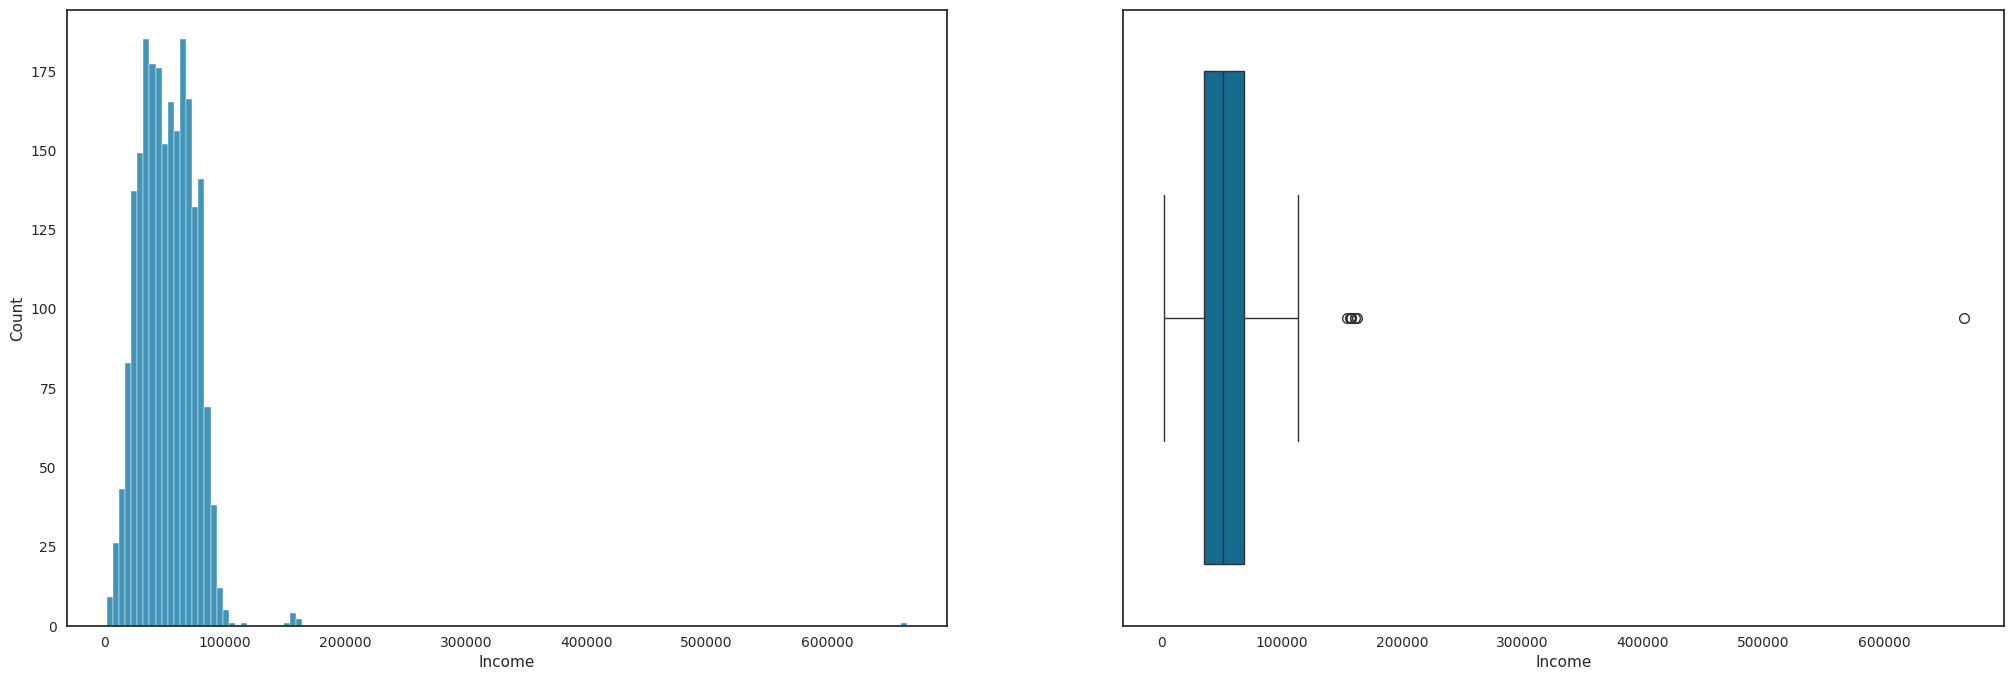

In [ ]:
# Checks the distribution of income to decide how to treat the missing values
sns.set_style("white")
print("Income")
print('Skewness: ', data_cleaned['Income'].skew())
plt.figure(figsize=(25,8))
plt.subplot(1,2,1)
sns.histplot(data_cleaned['Income'])
plt.subplot(1,2,2)
sns.boxplot(x=data_cleaned['Income'])




In [ ]:
#This code replaces missing values in Income column
data_cleaned['Income'] = data_cleaned['Income'].fillna(data_cleaned['Income'].median())



In [ ]:
data_cleaned.isna().sum()

,0
Year_Birth,0
Education,0
Marital_Status,0
Income,0
Kidhome,0
Teenhome,0
Dt_Customer,0
Recency,0
MntWines,0
MntFruits,0


##### **Observations:**



*  Income column was missing 24 data points
*  The Income data was plotted in a histrogram and a boxplot to observe the distribution and skewness was a calculated. The 6.7 skew shows that the data is heavily right-skewed. There are also outliers.
*   Because the income data is significantly right-skewed, the missing values were filled with the median income.
*   A check was performed and there are no longer missing values in the data set





#### **Question 4**: Are there any duplicates in the data?

In [ ]:
# Write your code here
data_cleaned.duplicated().sum()

np.int64(182)

In [ ]:
data_cleaned=data_cleaned[~data_cleaned.duplicated()]

In [ ]:
data_cleaned.duplicated().sum()

np.int64(0)

##### **Observations:**



*   There were 182 duplicates in this data set
*   The duplicates were dropped and a check confirms zero missing values




## **Exploratory Data Analysis**

### Univariate Analysis

#### **Question 5:** Explore all the variables and provide observations on their distributions. (histograms and boxplots)

In [ ]:
# Write your code here
col_headings = data_cleaned.columns.to_list()

Year_Birth
Skewness:  -0.3761633445265133


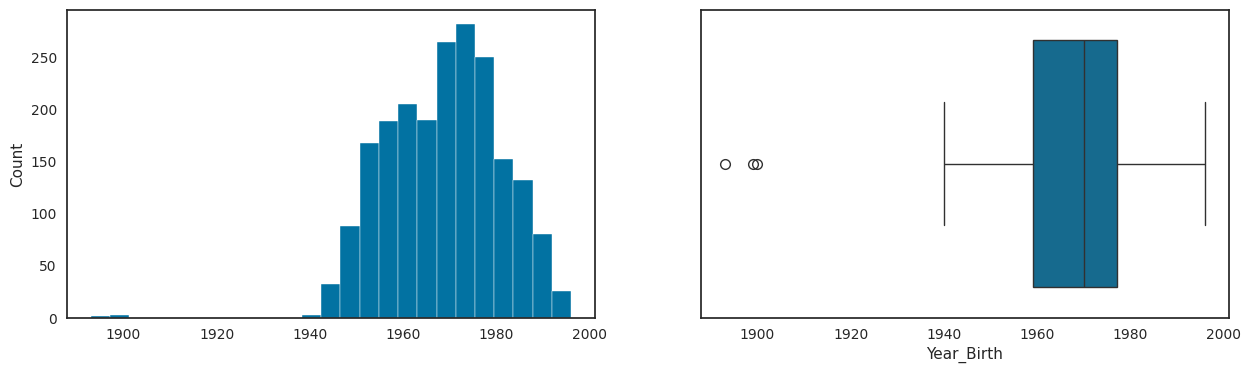

Skipping numerical analysis for non-numeric column: Education
Skipping numerical analysis for non-numeric column: Marital_Status
Income
Skewness:  7.100839342833025


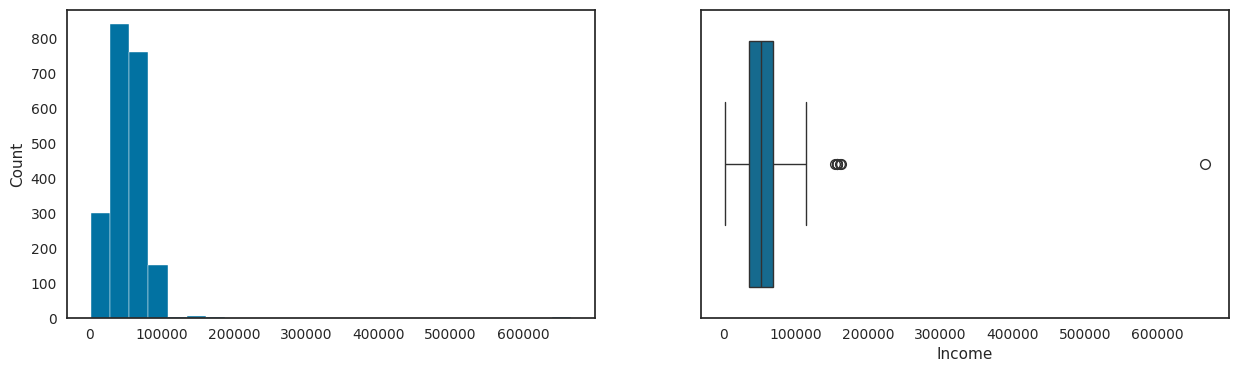

Kidhome
Skewness:  0.6214528097916001


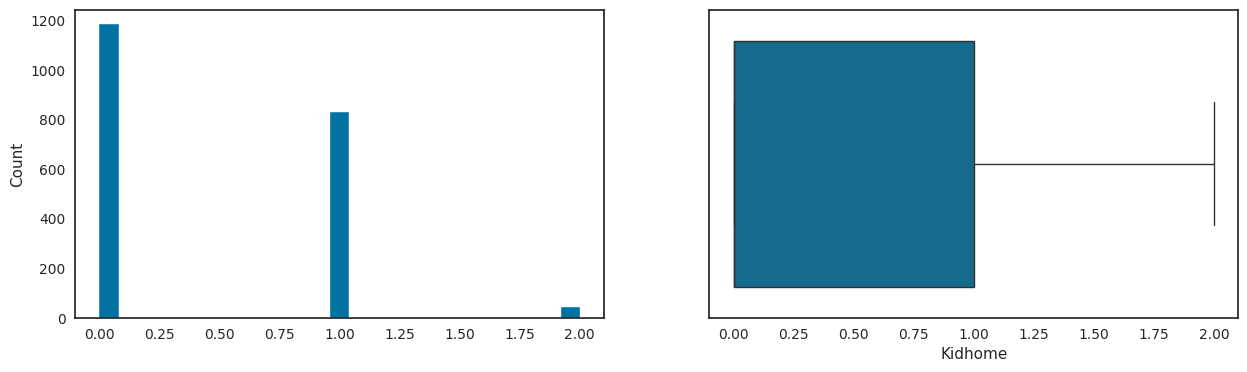

Teenhome
Skewness:  0.41065993264050915


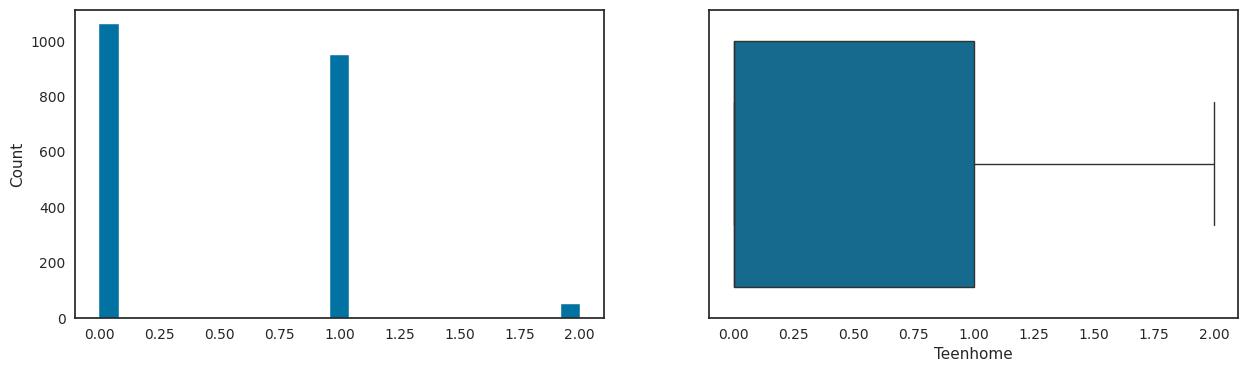

Skipping numerical analysis for non-numeric column: Dt_Customer
Recency
Skewness:  0.00212480179578336


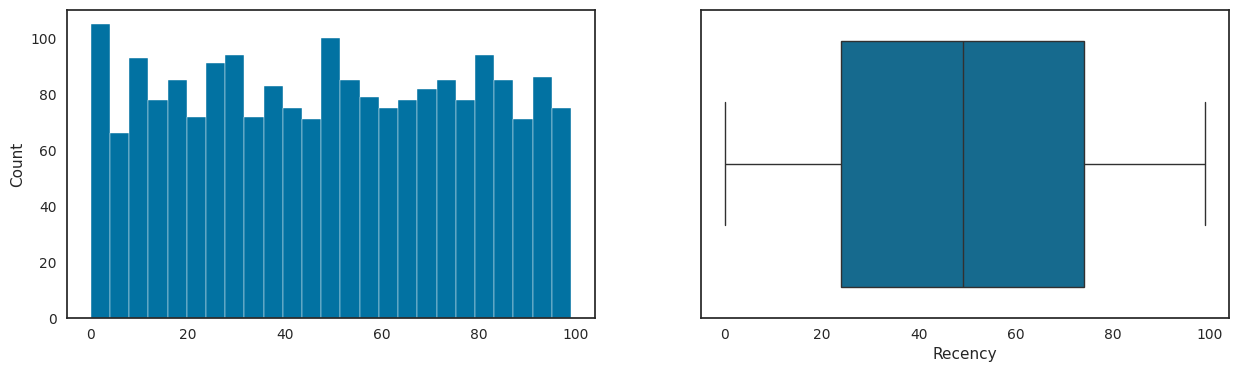

MntWines
Skewness:  1.174421075207337


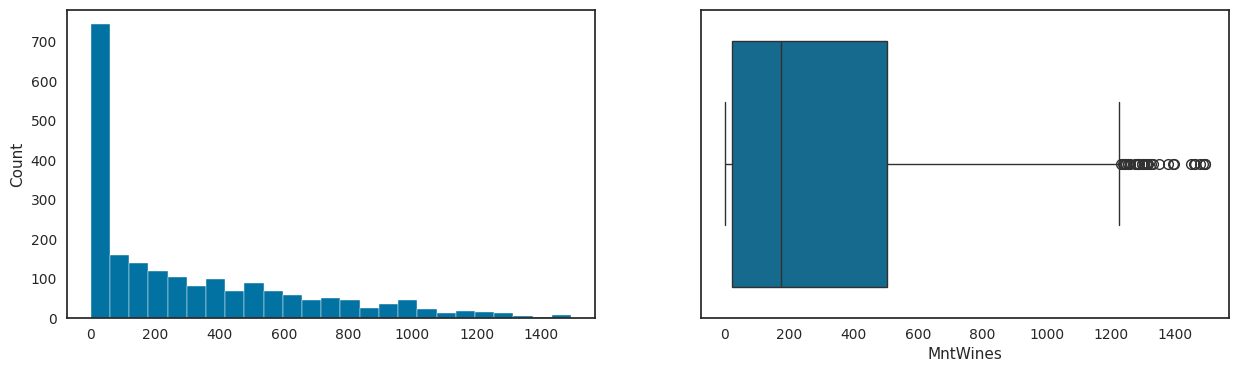

MntFruits
Skewness:  2.108111757040463


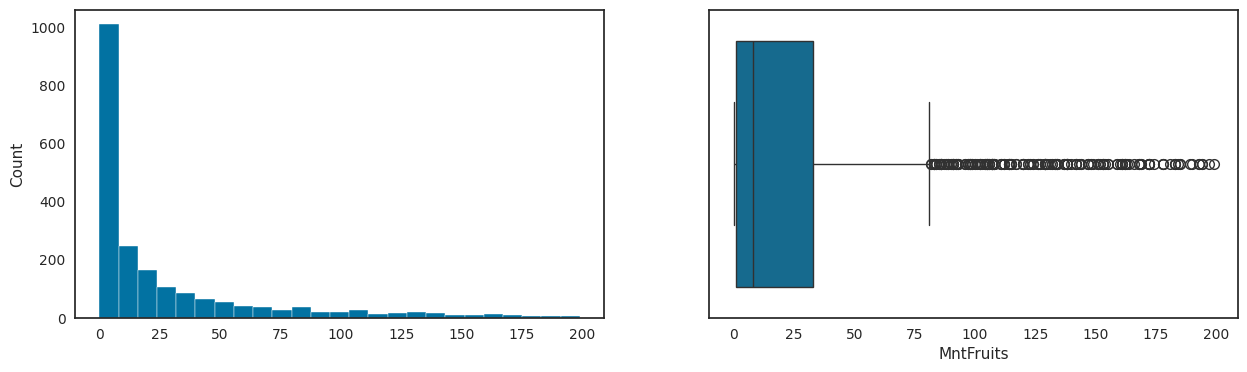

MntMeatProducts
Skewness:  2.1045798322244997


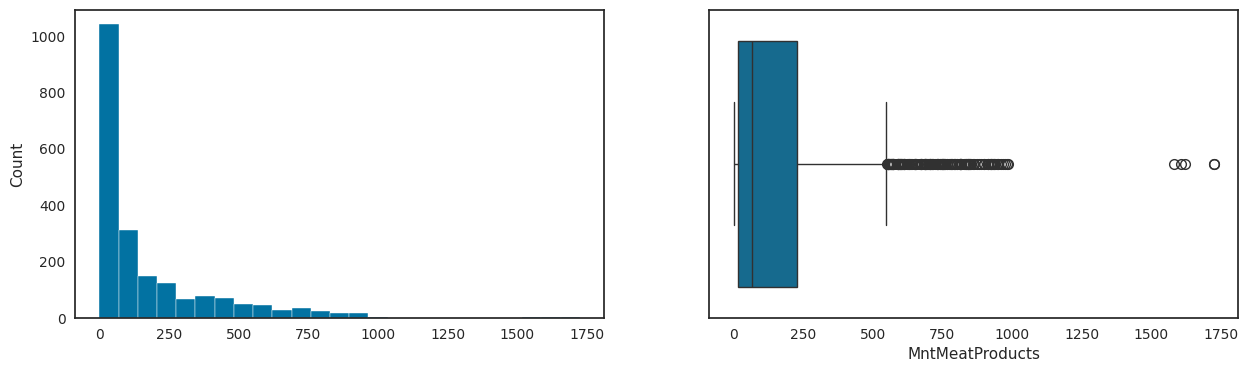

MntFishProducts
Skewness:  1.9306428811361163


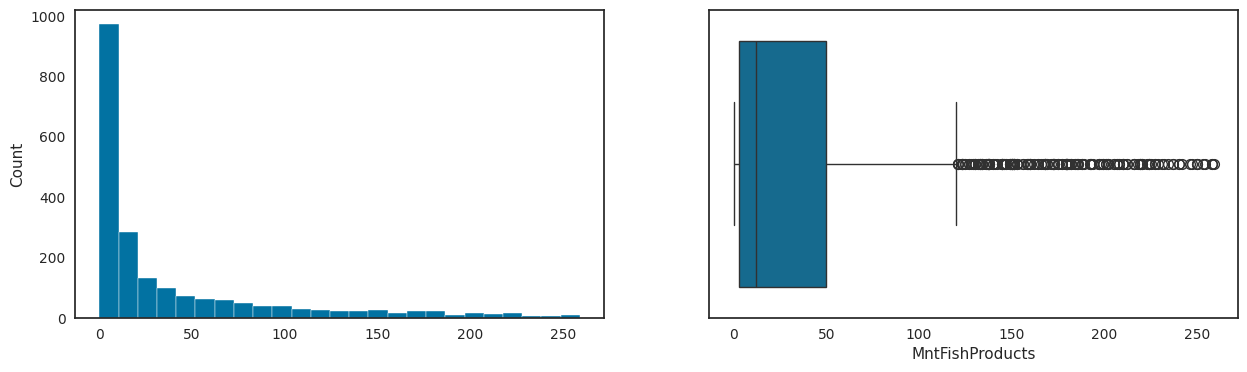

MntSweetProducts
Skewness:  2.150130477350209


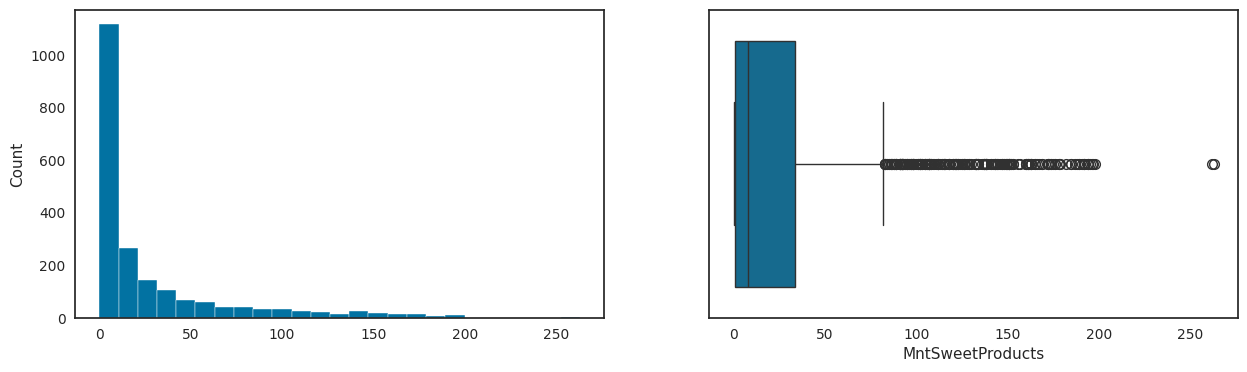

MntGoldProds
Skewness:  1.905061490807428


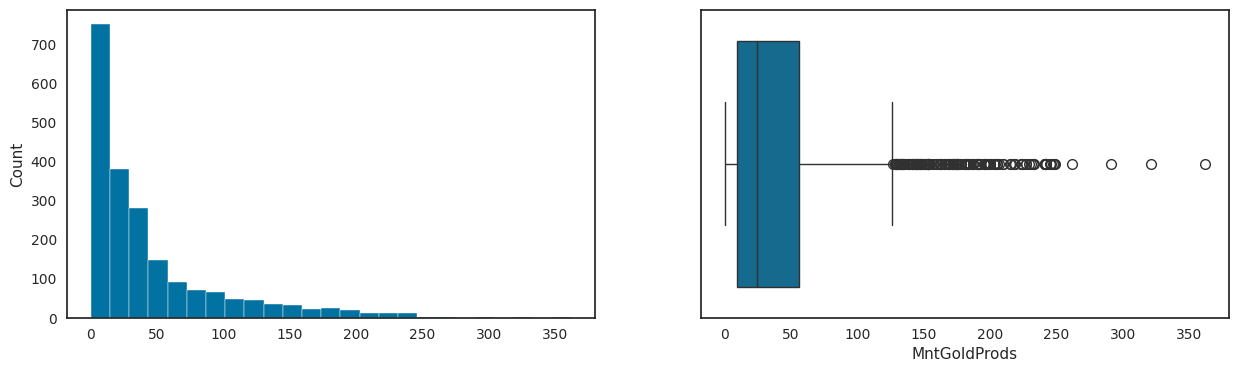

NumDealsPurchases
Skewness:  2.4393960499278142


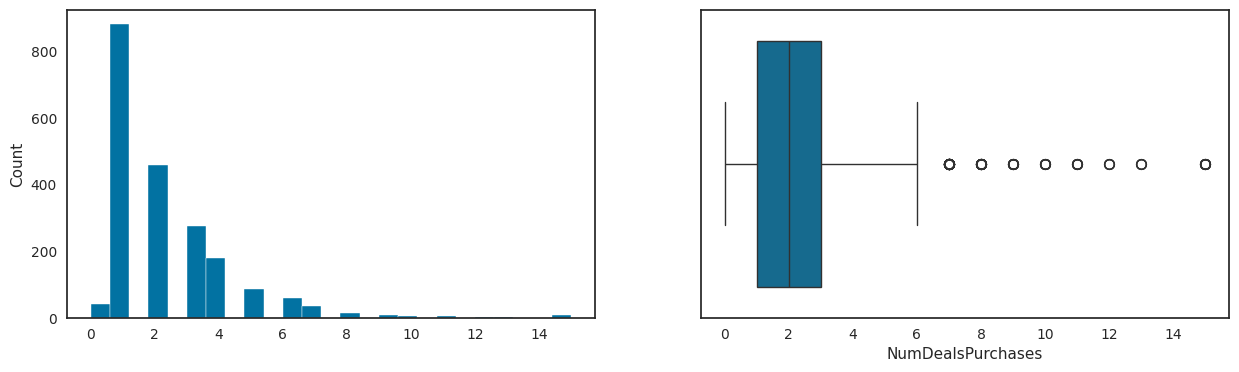

NumWebPurchases
Skewness:  1.426380029346788


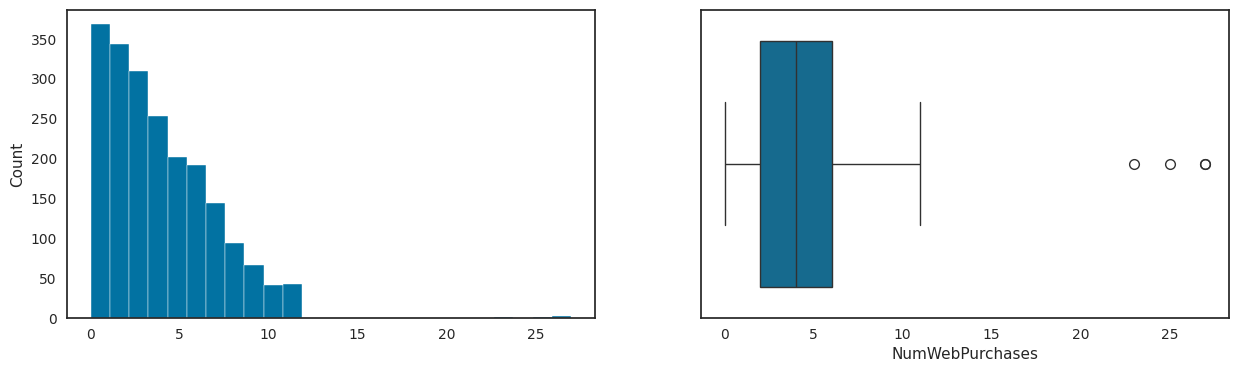

NumCatalogPurchases
Skewness:  1.9509376923001416


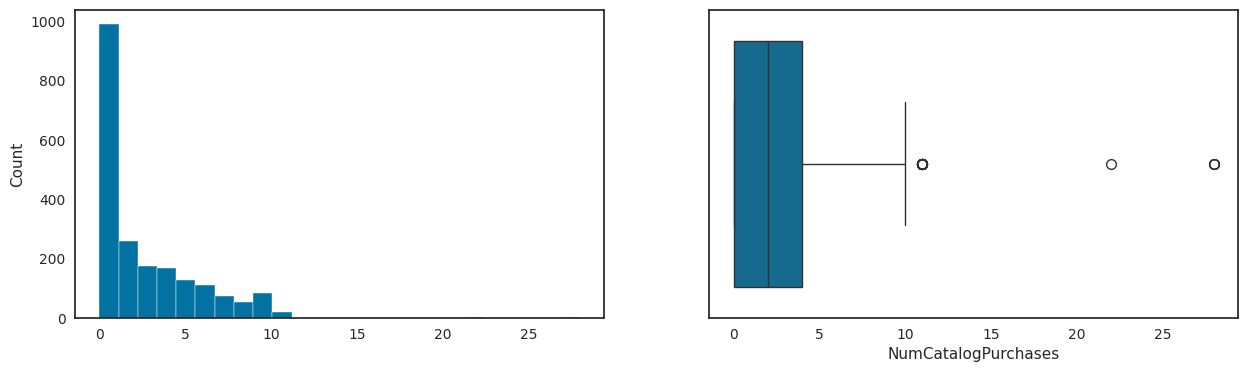

NumStorePurchases
Skewness:  0.7015123931395358


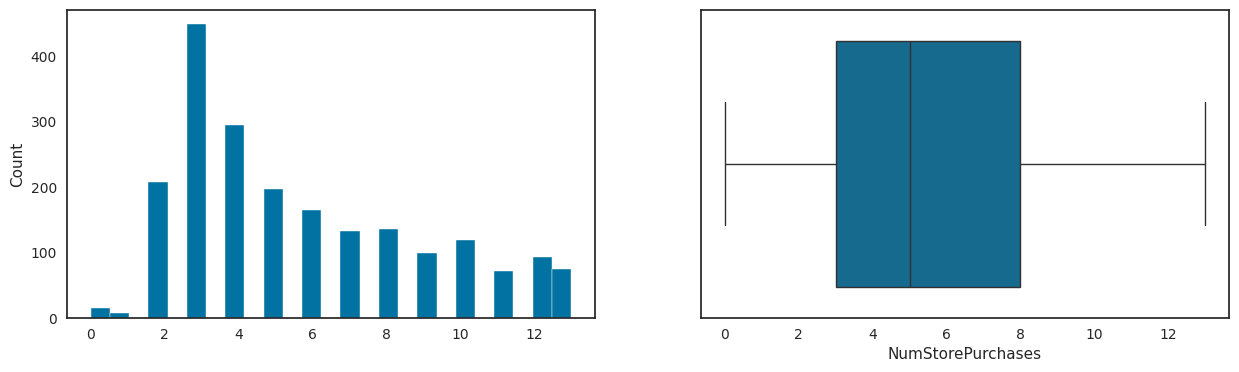

NumWebVisitsMonth
Skewness:  0.2526350649062449


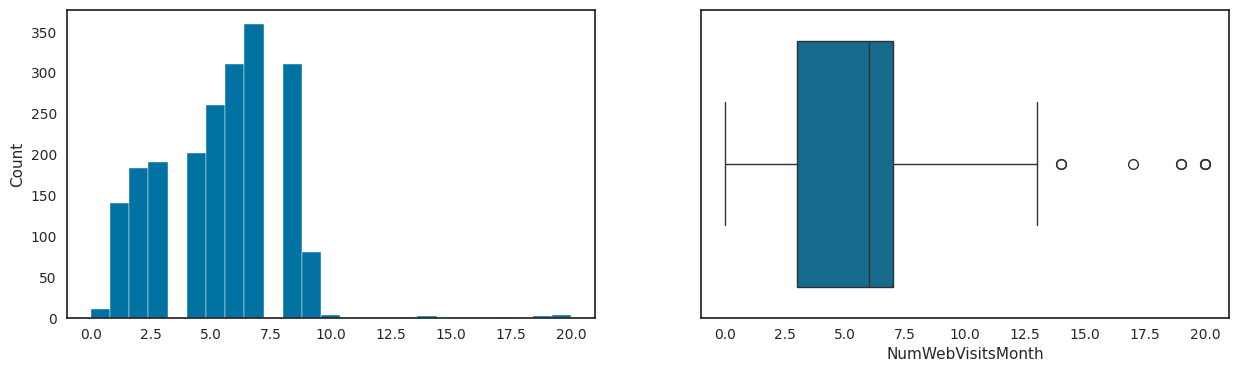

AcceptedCmp3
Skewness:  3.274744430114073


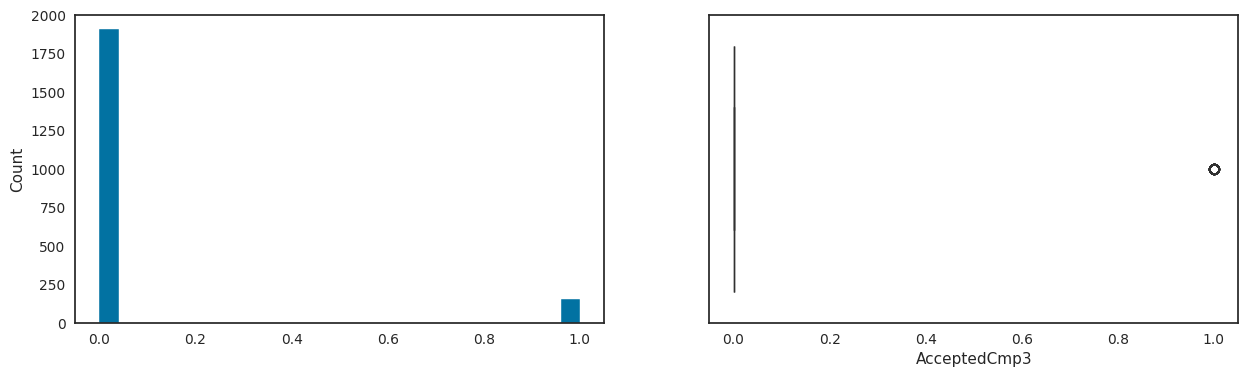

AcceptedCmp4
Skewness:  3.181702194183904


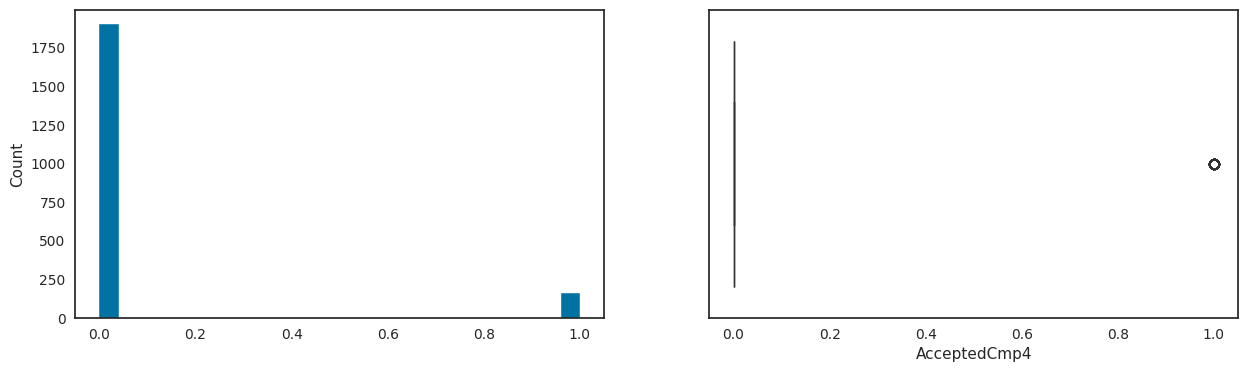

AcceptedCmp5
Skewness:  3.3164624427030103


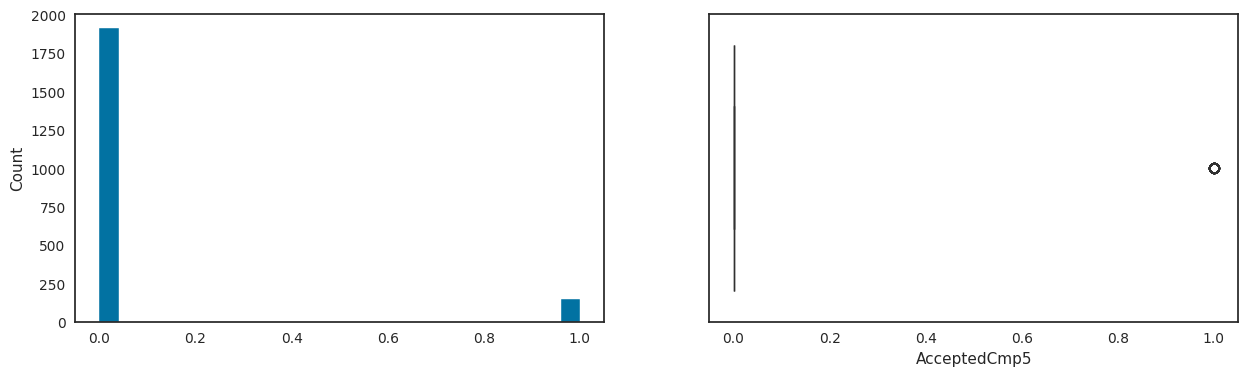

AcceptedCmp1
Skewness:  3.511783296602639


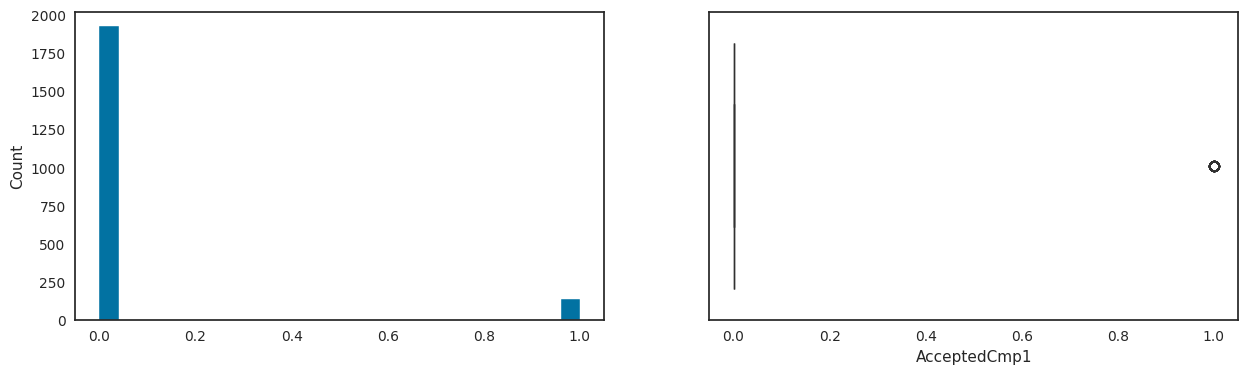

AcceptedCmp2
Skewness:  8.73371716750111


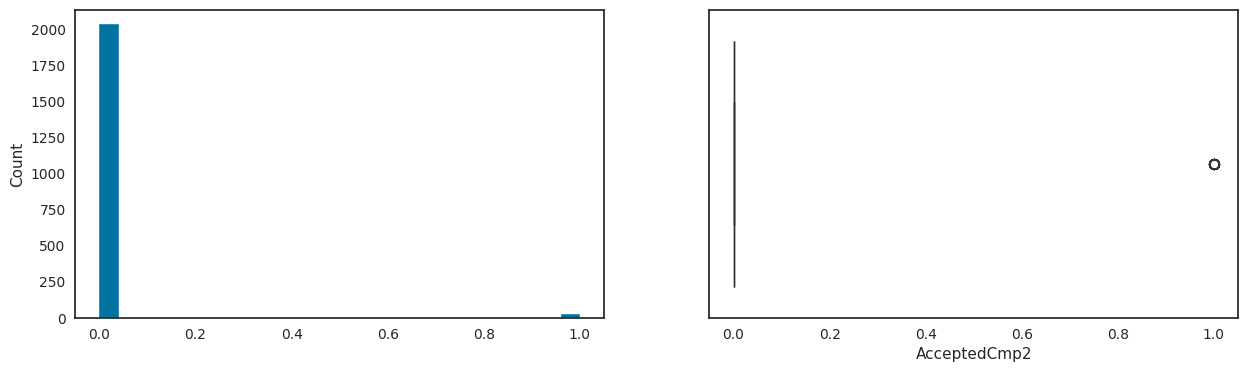

Complain
Skewness:  10.002781793843093


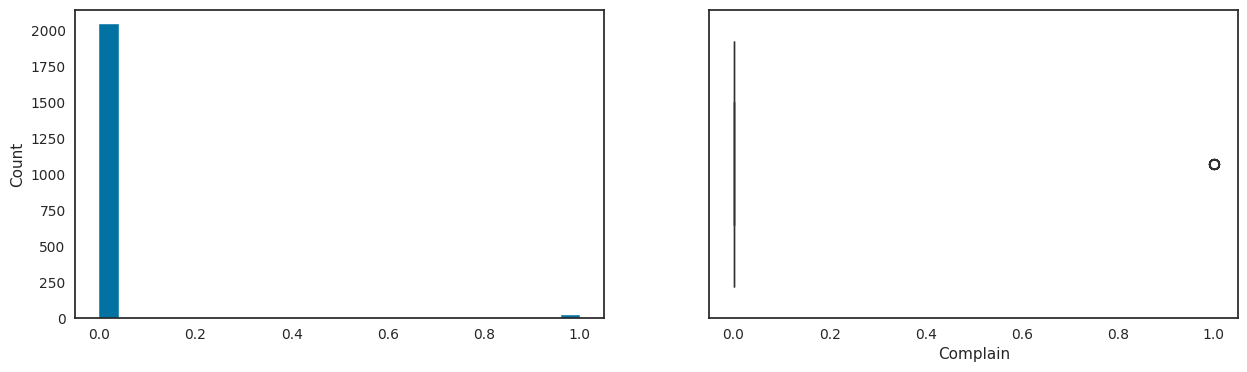

Z_CostContact
Skewness:  0.0


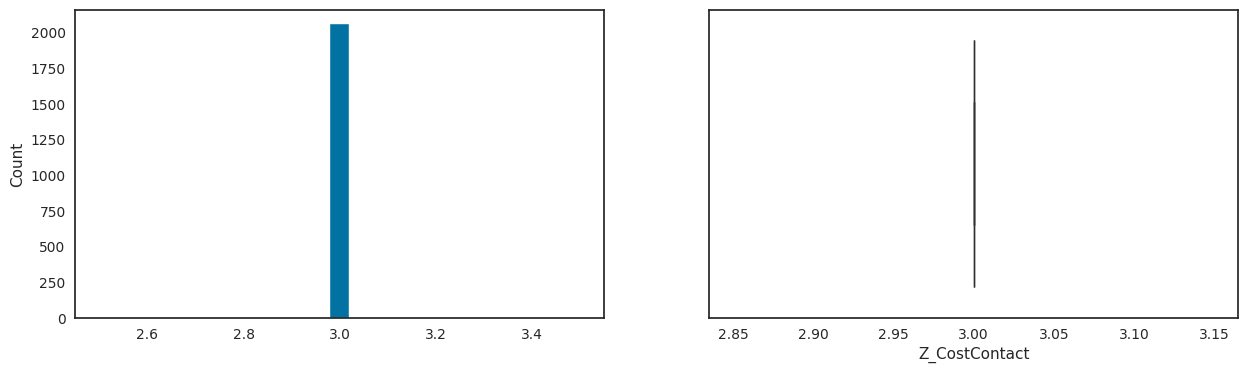

Z_Revenue
Skewness:  0.0


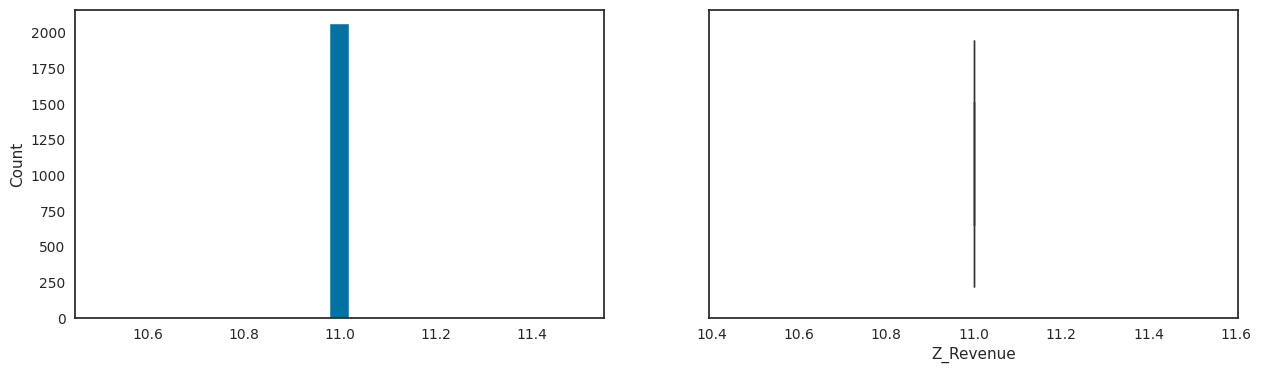

Response
Skewness:  1.939053779143764


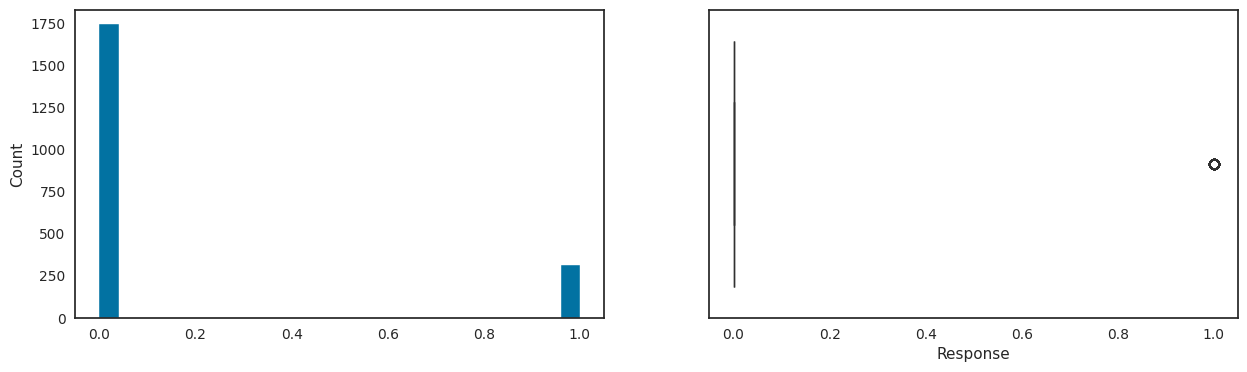

In [ ]:


#Distribution for each column
for col in col_headings:
  # Check if the column is numerical before attempting to calculate skewness and plot numerical distributions
  if pd.api.types.is_numeric_dtype(data_cleaned[col]):
    print(col)
    print('Skewness: ', data_cleaned[col].skew())
    plt.figure(figsize=(15,4))
    plt.subplot(1,2,1)
    data_cleaned[col].hist(bins=25, grid=False)
    plt.ylabel('Count')
    plt.subplot(1,2,2)
    sns.boxplot(x=data_cleaned[col])
    plt.show()
  else:
    print(f"Skipping numerical analysis for non-numeric column: {col}")
    # Optional: Add code here to visualize categorical columns, e.g., using a countplot
    #plt.figure(figsize=(10,4))
    #sns.countplot(y=data_cleaned[col])
    #plt.title(f'Distribution of {col}')
    #plt.show()

##### **Observations:**


*  Majority of customers were aboorn between 1940 and 1995 with a few exception of cuctomers born in 1900s






*    The income distribution is right-skewed with outliers around $150000 and around $650000

*   There are almost 1200 customers with no kids , followed with second majority of customers who have 1 kid and a small number (less than 100) of customers with 2 kids in their families.

*   The Teenhome follows a similar trend as the Kidhome column
*  There Recency column has approximetly zero skew and is therefore symmetrical. This column also has a uniform distribution.

*   There is a right-skewness and outliers in the following columns: MntWines, MntFruits, MntMeatProducts, MntFishProducts, MntSweetProducts, and MntGoldProds. The majority of customers bought 50 wines, 6 fruits, 50 meat products, 10 fish products, 5 sweets products, and about 12 gold products.

*   There is right-skewness in NumWebPurchases, NumDealsPurchases, and NumCatalogPurchases.

*   Majority customers made 3 in-stores purchases

*   The NumWebVisitsMonth column is almost symmetrical. There are some outliers









### Bivariate Analysis

#### **Question 6:** Perform multivariate analysis to explore the relationsips between the variables.

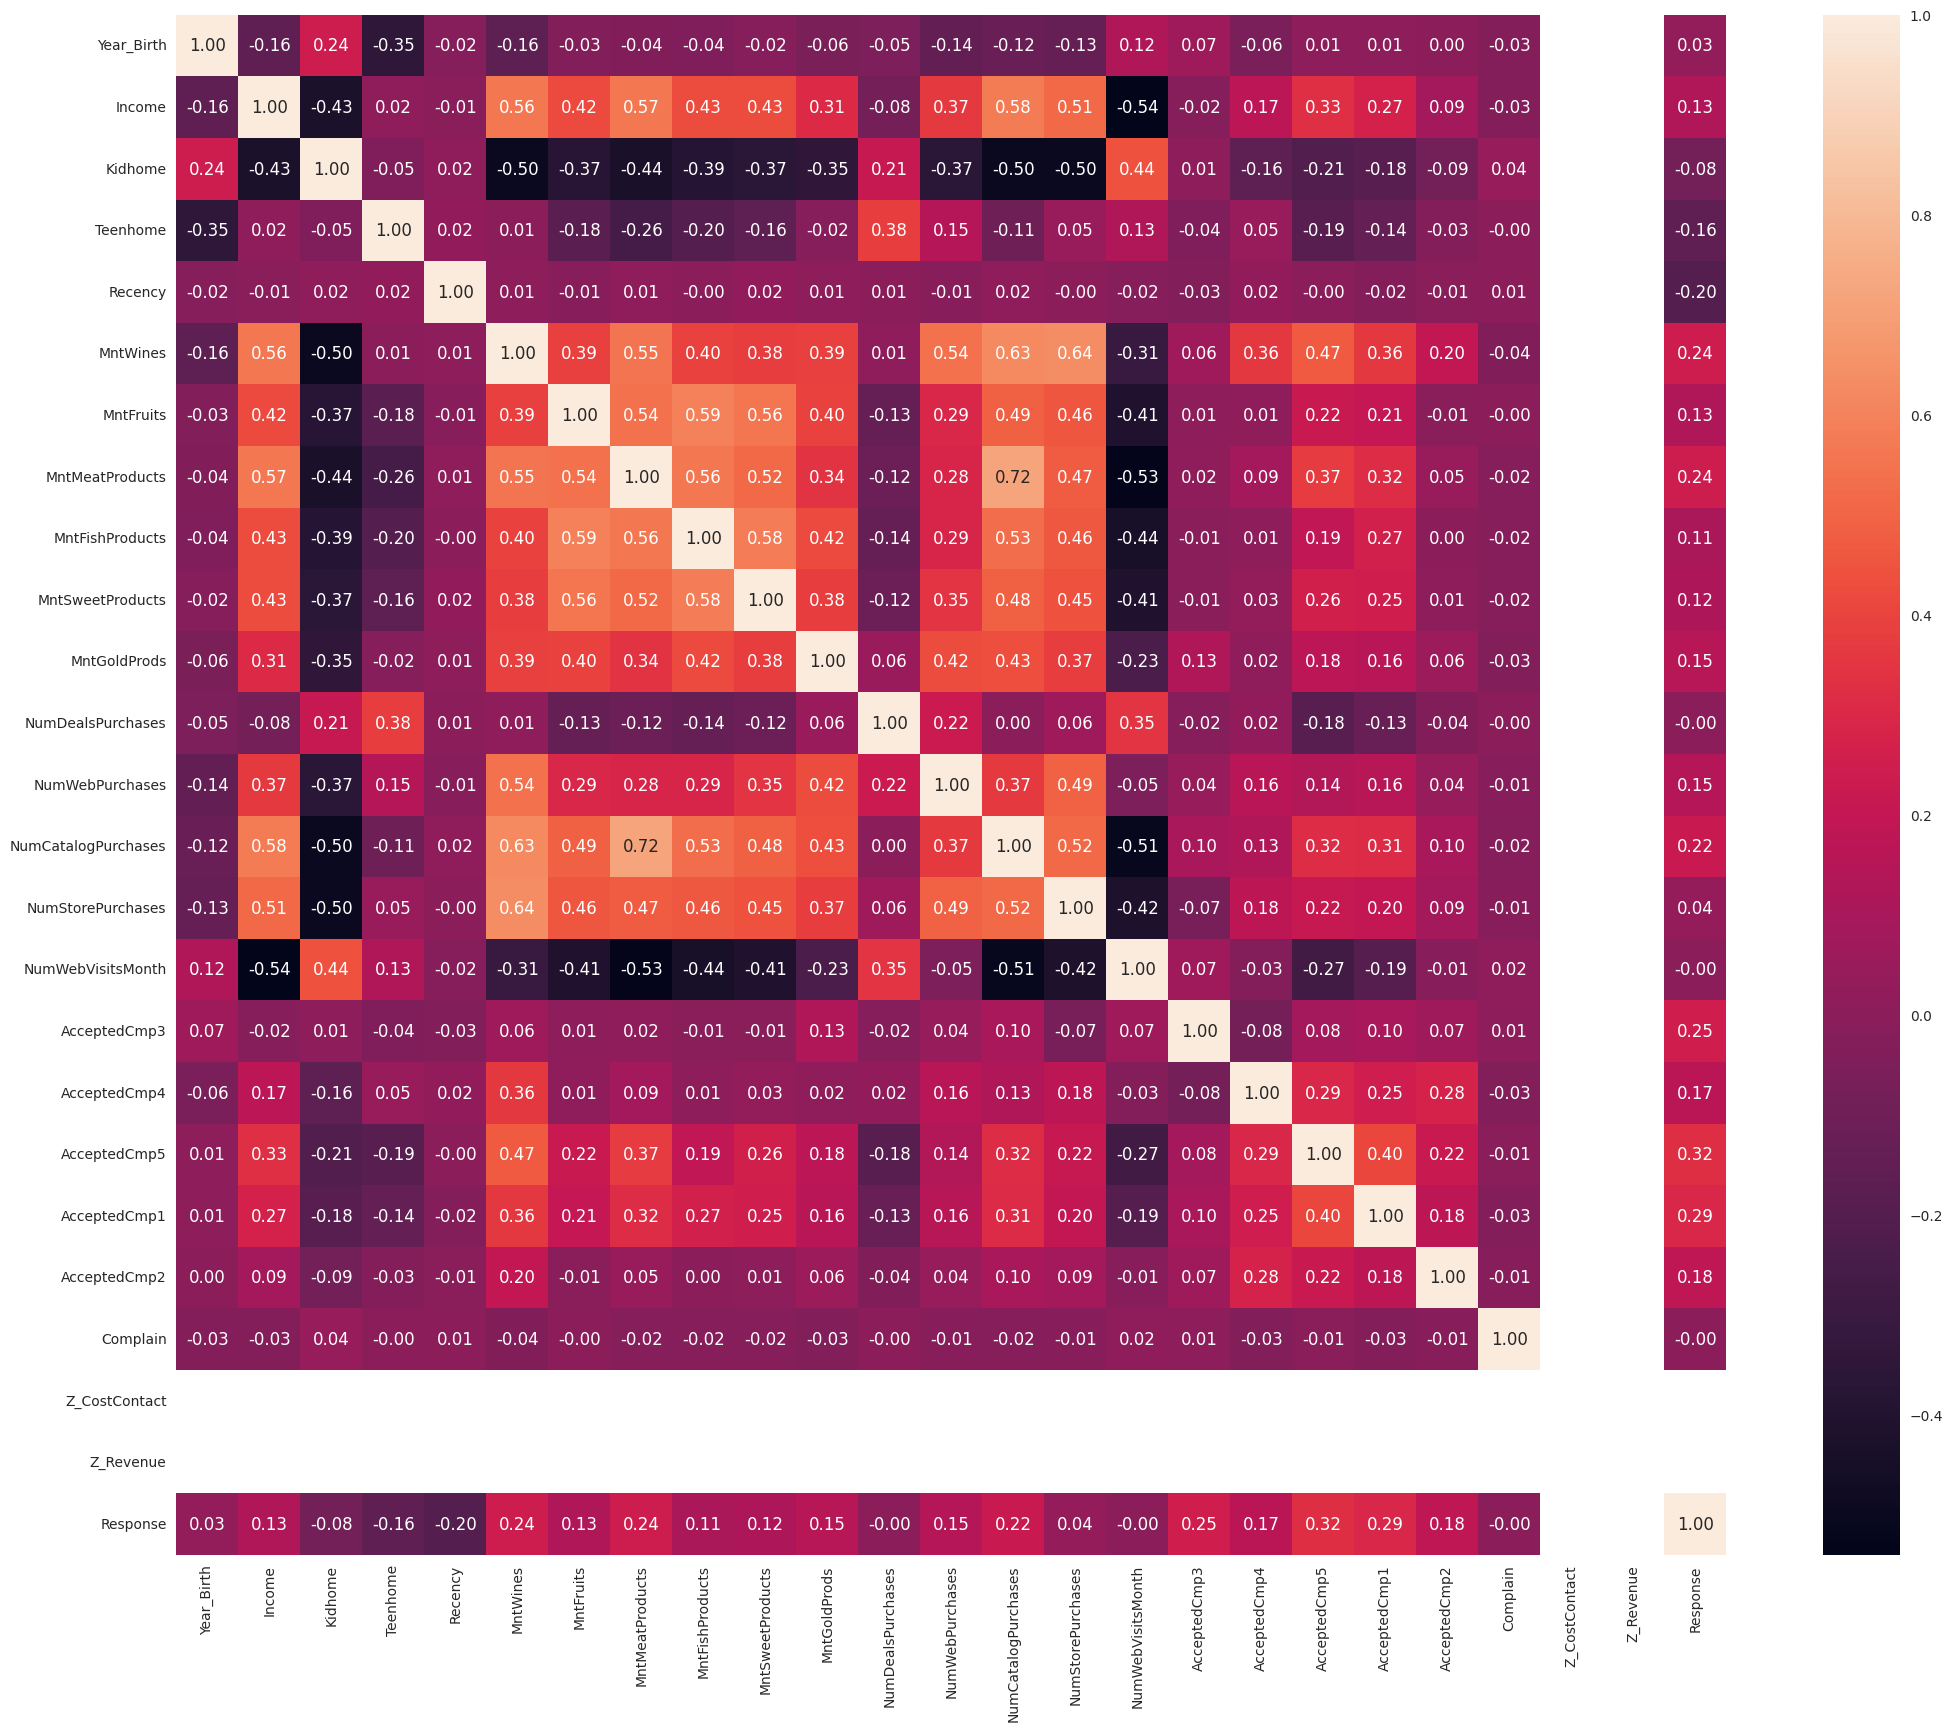

In [ ]:
import numpy as np

# Get only numeric columns for correlation
numeric_data = data_cleaned.select_dtypes(include=np.number)

plt.figure(figsize=(25,20))
sns.heatmap(numeric_data.corr(), annot=True, fmt='.2f')
plt.show()

##### **Observations:**
Positive correlations :

*   Income is positively correlated with NumCatalog Purchase and NumStorePurchase
*   Income is also positively correlated with MntWines and MntMeatProducts

*   MntWines is correlated with NumStorePurchases, NumCatalogPurchase, and NumWebPurchses

*   MntWines is also positively correlated with MntMeatProducts meaning that people who buy wine also byu meat.

*   MntFruit is positively correlated with MntSweetProducts, MntFishProducts, and MntMeatsProducts. This means that people shop for from one these categories also shop from the other two.
*   There is a positive correlation between MntMeatProducts and NumCatalogPurchases


*   There is a positive correlation between MntFishProducts and MntSweetProducts
*   There is a positive correlation between NumFishProducts and NumCatalogPurchases


*   There is a positive correlation betwen NumCatalogPurchase and NuStorePurchase
*   List item


Negative correletions:


*   Income is negatively correlated and NumWebVisitsMonth

*   MntMeatProducts is negatively correlated with NumWebVisitsMonth. This implies that people don't come to the online store to buy meat
*   NumCatalogPurchases is negatively correlated with NumWebVisitsMonth.


*   KidHome is negatively correlated with NumCatalogPurchases and NumStorePurchases.






## **K-means Clustering**

#### **Question 7** : Select the appropriate number of clusters using the elbow Plot. What do you think is the appropriate number of clusters?

In [ ]:
# Drop object columns from data_cleaned to keep only numerical columns
data_num = data_cleaned.select_dtypes(exclude=['object'])

# Display the first few rows of the new DataFrame to confirm
data_num.head()

,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,1957,58138.0,0,0,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1
1,1954,46344.0,1,1,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0
2,1965,71613.0,0,0,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0
3,1984,26646.0,1,0,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0
4,1981,58293.0,1,0,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0


In [ ]:
#

scaler = StandardScaler()
data_scaled = pd.DataFrame(scaler.fit_transform(data_num), columns=data_num.columns)

In [ ]:
data_scaled.head()

,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,-0.984645,0.228270,-0.829097,-0.932051,0.312088,0.984044,1.554193,1.657389,2.464511,1.458453,0.846738,0.340203,1.394889,2.502177,-0.546780,0.688830,-0.281393,-0.288371,-0.278365,-0.264958,-0.113116,-0.099063,0.0,0.0,2.361161
1,-1.235251,-0.236579,1.031625,0.898255,-0.377754,-0.870634,-0.634978,-0.708461,-0.646539,-0.627684,-0.726738,-0.174604,-1.107885,-0.566237,-1.164383,-0.131073,-0.281393,-0.288371,-0.278365,-0.264958,-0.113116,-0.099063,0.0,0.0,-0.423521
2,-0.316363,0.759375,-0.829097,-0.932051,-0.791659,0.362846,0.572841,-0.178335,1.348193,-0.148113,-0.035944,-0.689411,1.394889,-0.225302,1.306029,-0.541024,-0.281393,-0.288371,-0.278365,-0.264958,-0.113116,-0.099063,0.0,0.0,-0.423521
3,1.270808,-1.012958,1.031625,-0.932051,-0.791659,-0.870634,-0.559489,-0.647124,-0.500137,-0.579727,-0.745927,-0.174604,-0.750346,-0.907172,-0.546780,0.278878,-0.281393,-0.288371,-0.278365,-0.264958,-0.113116,-0.099063,0.0,0.0,-0.423521
4,1.020202,0.234379,1.031625,-0.932051,1.553804,-0.389131,0.421863,-0.217766,0.158674,-0.004241,-0.554040,1.369817,0.322272,0.115633,0.070823,-0.131073,-0.281393,-0.288371,-0.278365,-0.264958,-0.113116,-0.099063,0.0,0.0,-0.423521


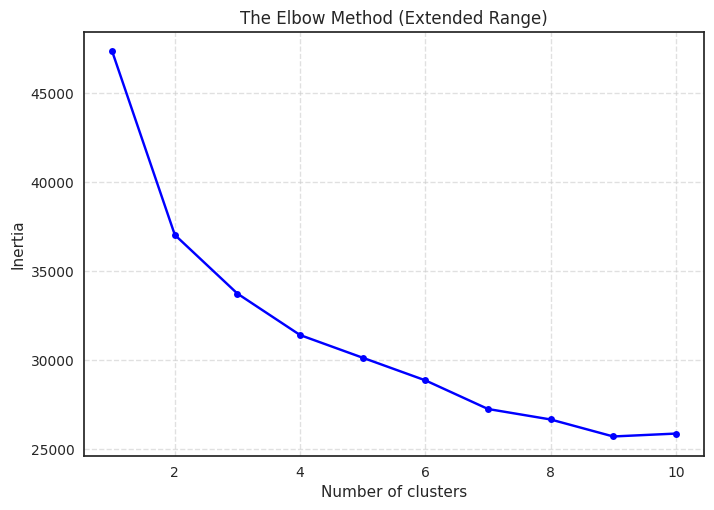

In [ ]:
iner_dict = {}
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, max_iter=1000).fit(data_scaled)
    iner_dict[i]= kmeans.inertia_

plt.figure()
plt.plot(list(iner_dict.keys()), list(iner_dict.values()), marker='o', linestyle='-', markersize=5, color='blue')
plt.title('The Elbow Method (Extended Range)')
plt.xlabel('Number of clusters')
plt.ylabel('Inertia')
plt.grid(True, linestyle='--', alpha=0.6)

plt.show()

##### **Observations:**
The first elbow point shows up at number of clusters = 2

#### **Question 8** : finalize appropriate number of clusters by checking the silhoutte score as well. Is the answer different from the elbow plot?

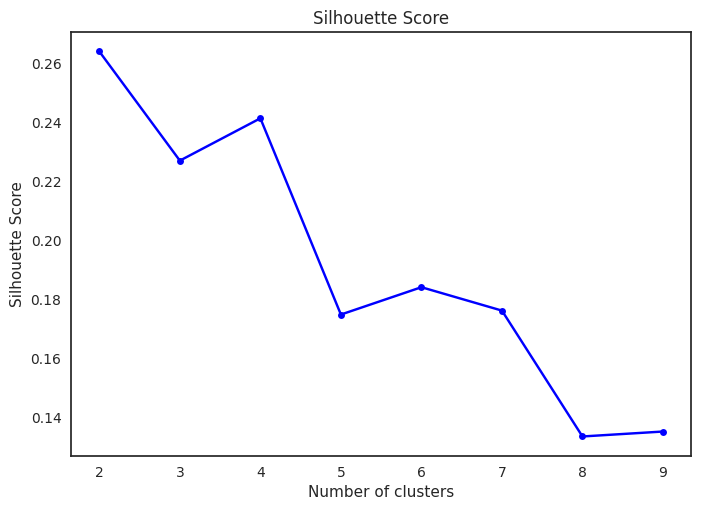

In [ ]:
# Silhhoutte analysis to eveluate k-means clustering
sc={}
for i in range(2,10):
  kmeans=KMeans(n_clusters=i).fit(data_scaled)
  sc[i]=silhouette_score(data_scaled,kmeans.labels_)

plt.figure()
plt.plot(list(sc.keys()),list(sc.values()),marker='o',linestyle='-',markersize=5,color='blue')
plt.title('Silhouette Score')
plt.xlabel('Number of clusters')
plt.ylabel('Silhouette Score')
plt.show()

##### **Observations:**
The highest point on the silhoutte score corresponds with 2 number of clusters.

This confirms the observation in elbow method above.

#### **Question 9**: Do a final fit with the appropriate number of clusters. How much total time does it take for the model to fit the data?

In [ ]:
data_scaled_copy=data_scaled.copy()
kmeans=KMeans(n_clusters=2, max_iter=1000, random_state=1).fit(data_scaled)

data_scaled_copy['Labels']=kmeans.predict(data_scaled)
data_num['Labels'] = kmeans.predict(data_scaled)

In [ ]:
data_num.Labels.value_counts()

,count
Labels,
1,1249
0,809


##### **Observations:**


*   Two labels were created for 2 clusters one with 809 observations and a second with 1249 observations.
*   It took less than a second to fit the model



## **Cluster Profiling and Comparison**

#### **Question 10**: Perform cluster profiling using boxplots for the K-Means algorithm. Analyze key characteristics of each cluster and provide detailed observations.

In [ ]:
# Write your code here
mean_per_label= data_num.groupby('Labels').mean()
median_per_label= data_num.groupby('Labels').median()
df_kmeans=pd.concat([mean_per_label,median_per_label],axis=0)
df_kmeans.index=['Gr_0 Mean','Gr_1 Mean','Gr_0 Median','Gr_1 Median']
df_kmeans.T

,Gr_0 Mean,Gr_1 Mean,Gr_0 Median,Gr_1 Median
Year_Birth,1966.961681,1969.969576,1967.0,1972.0
Income,72259.708282,39448.198559,71626.0,38829.0
Kidhome,0.065513,0.691753,0.0,1.0
Teenhome,0.427689,0.562050,0.0,1.0
Recency,49.192831,48.795837,50.0,49.0
MntWines,604.807169,109.032826,561.0,35.0
MntFruits,56.296663,6.763010,42.0,3.0
MntMeatProducts,367.545117,38.264211,300.0,21.0
MntFishProducts,80.030902,9.670937,63.0,4.0
MntSweetProducts,58.542645,6.860689,43.0,3.0


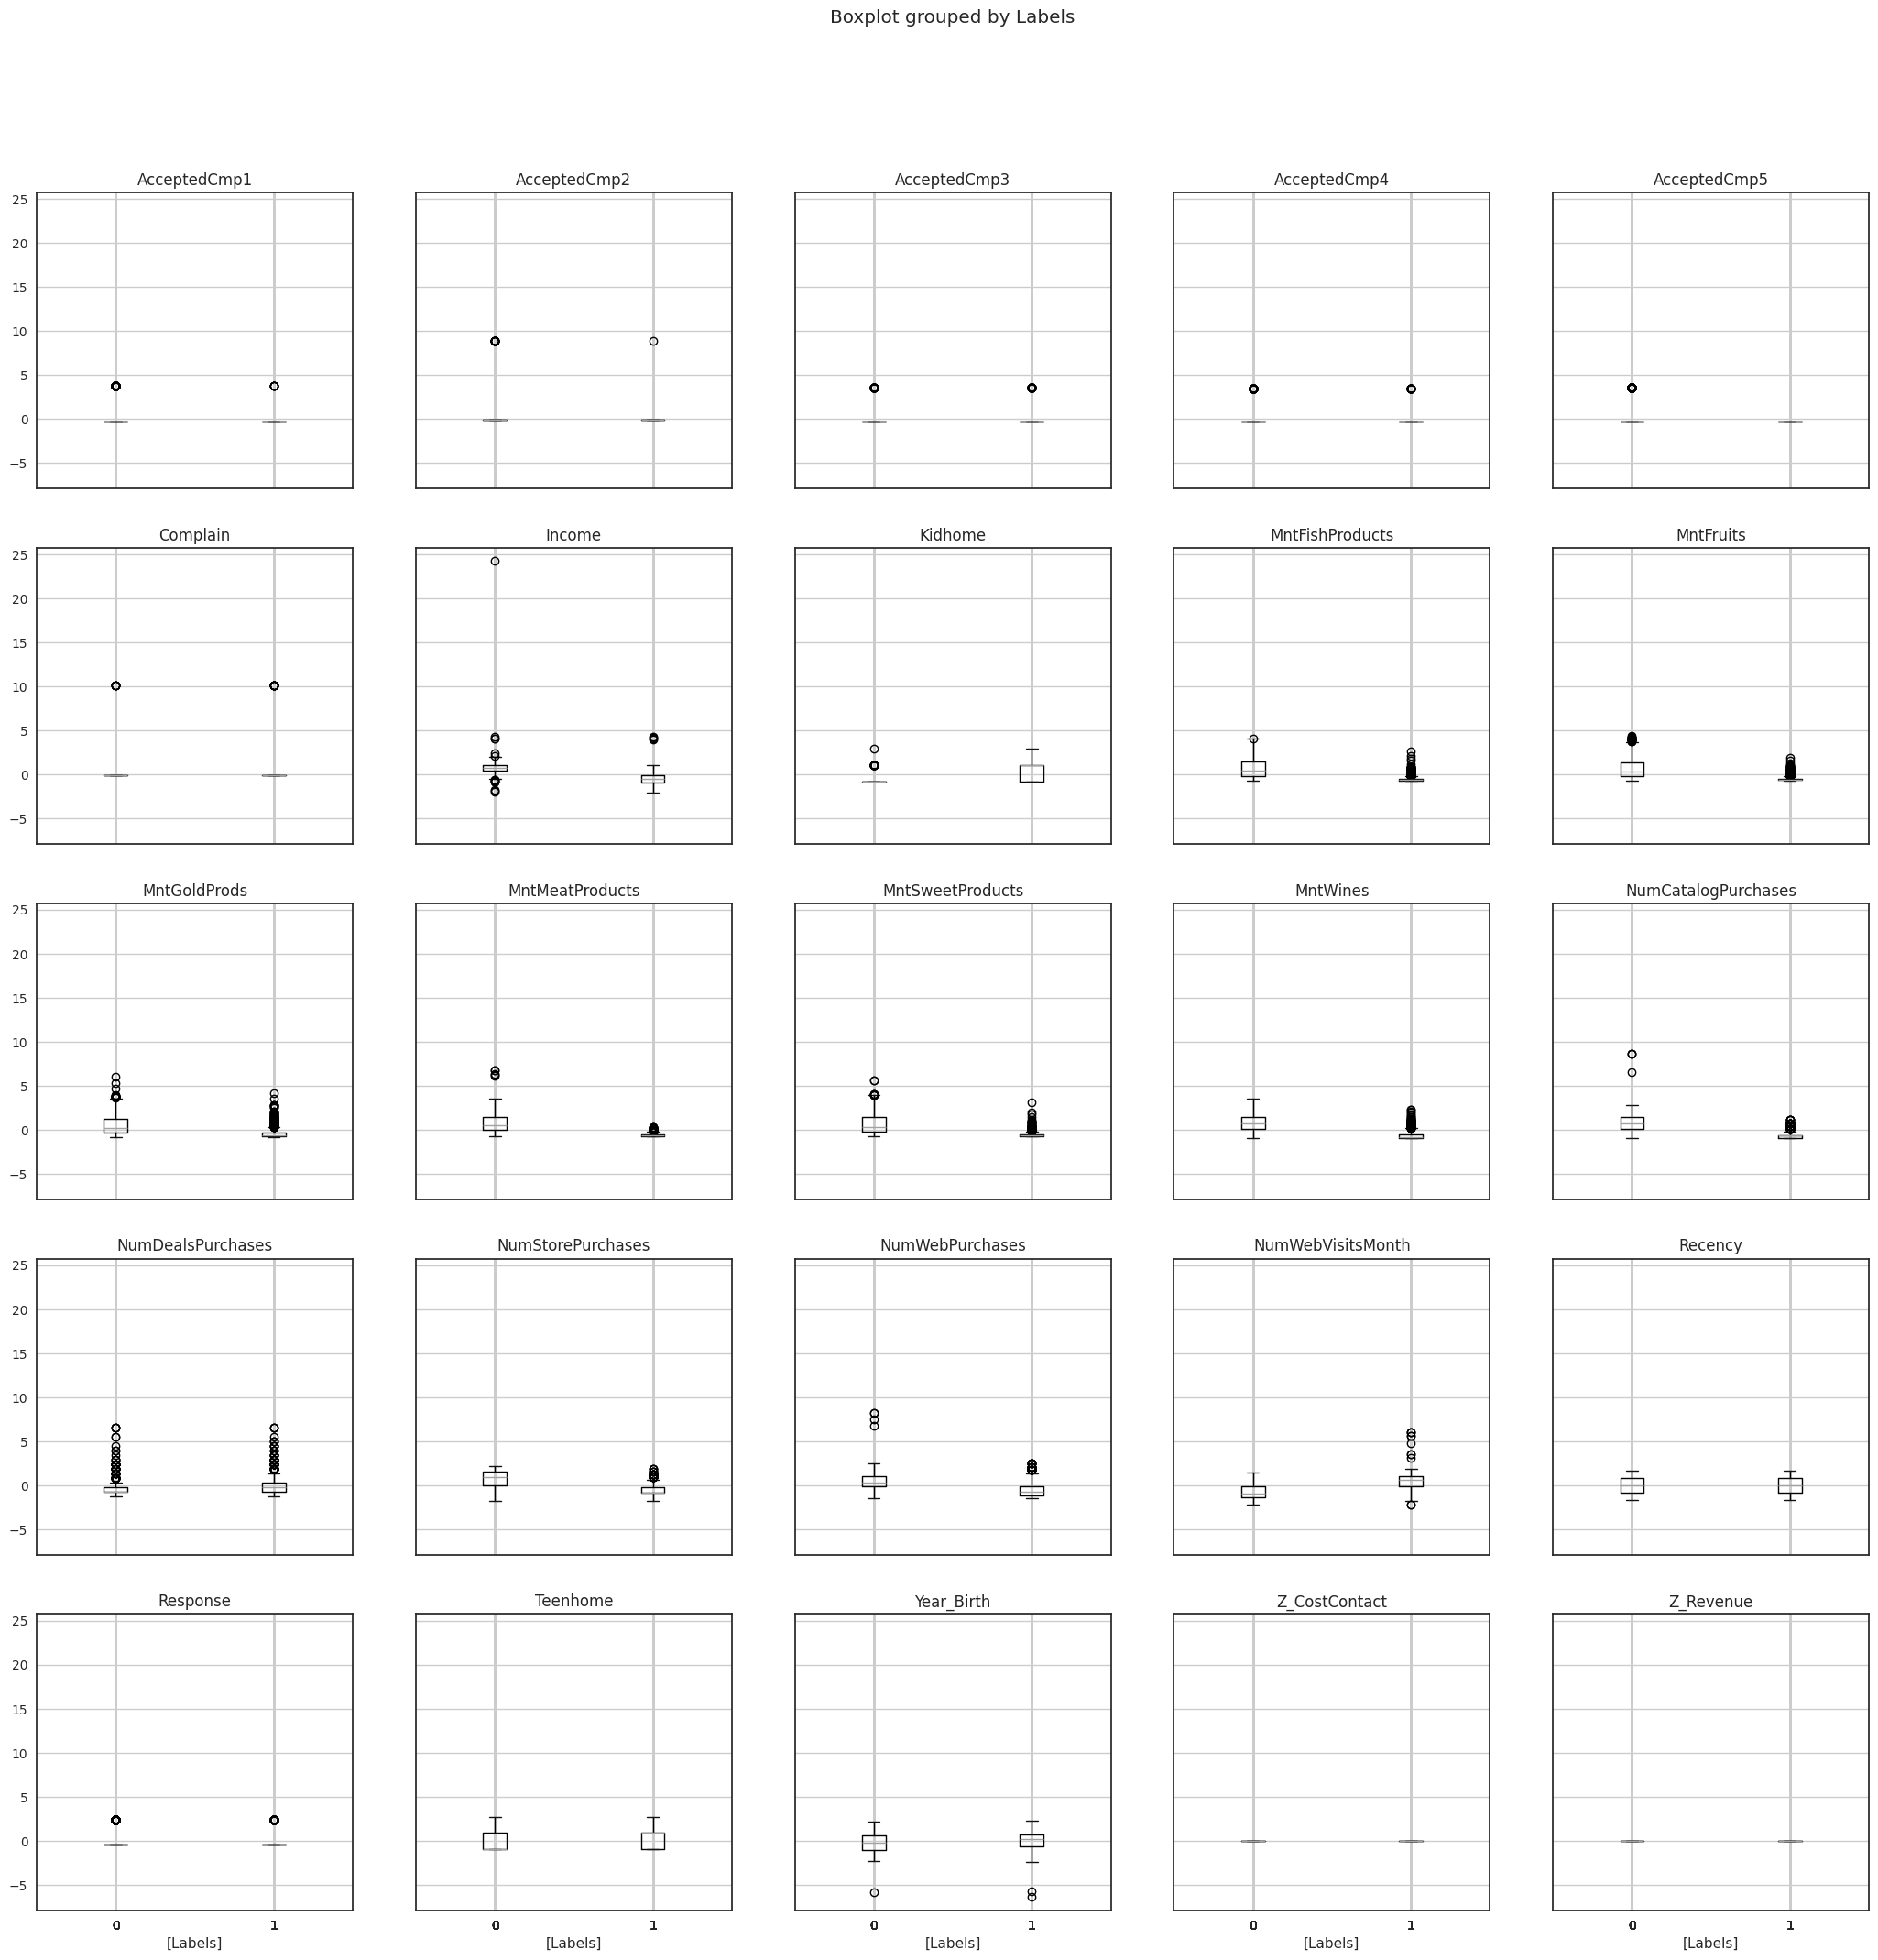

In [ ]:
data_scaled_copy.boxplot(by = 'Labels', layout=(5,5), figsize=(25,25))
plt.show()

##### **Observations:**


*   Group 0 is comprised of high income earners who tend to make more in-store (NumStorePurchase), catalog, and online (NumWebPurchases) purchases and make fewer monthly visits to the online store (NumWebvisitsMonth).Group 0 members have therefore bought the largest amount of meat products, fish, wines, sweets, fruits, and gold products. This makes sense since high earners have more spending power.Members of group 0 also have fewer kids (KidHome) compared to Group 1.

*   Group 1 members have lower income and more kids per home (KidHome) compared to Group 0. On average, they make more monthly web visits than  Group 0, however those visits are not reflected in their online spending habits. Members of Group 1 also make slightly more deal purchases (NumDealPurchase) than Group 0. Group 1 members are on average older than Group 0, though the difference isn't too big.


*   Based on the above boxplot, the remaining attributes are mostly equally distributed across the two groups.






#### **Question 11**: Perform cluster profiling on the data using a barplot for the K-Means algorithm. Provide insights and key observations for each cluster based on the visual analysis.

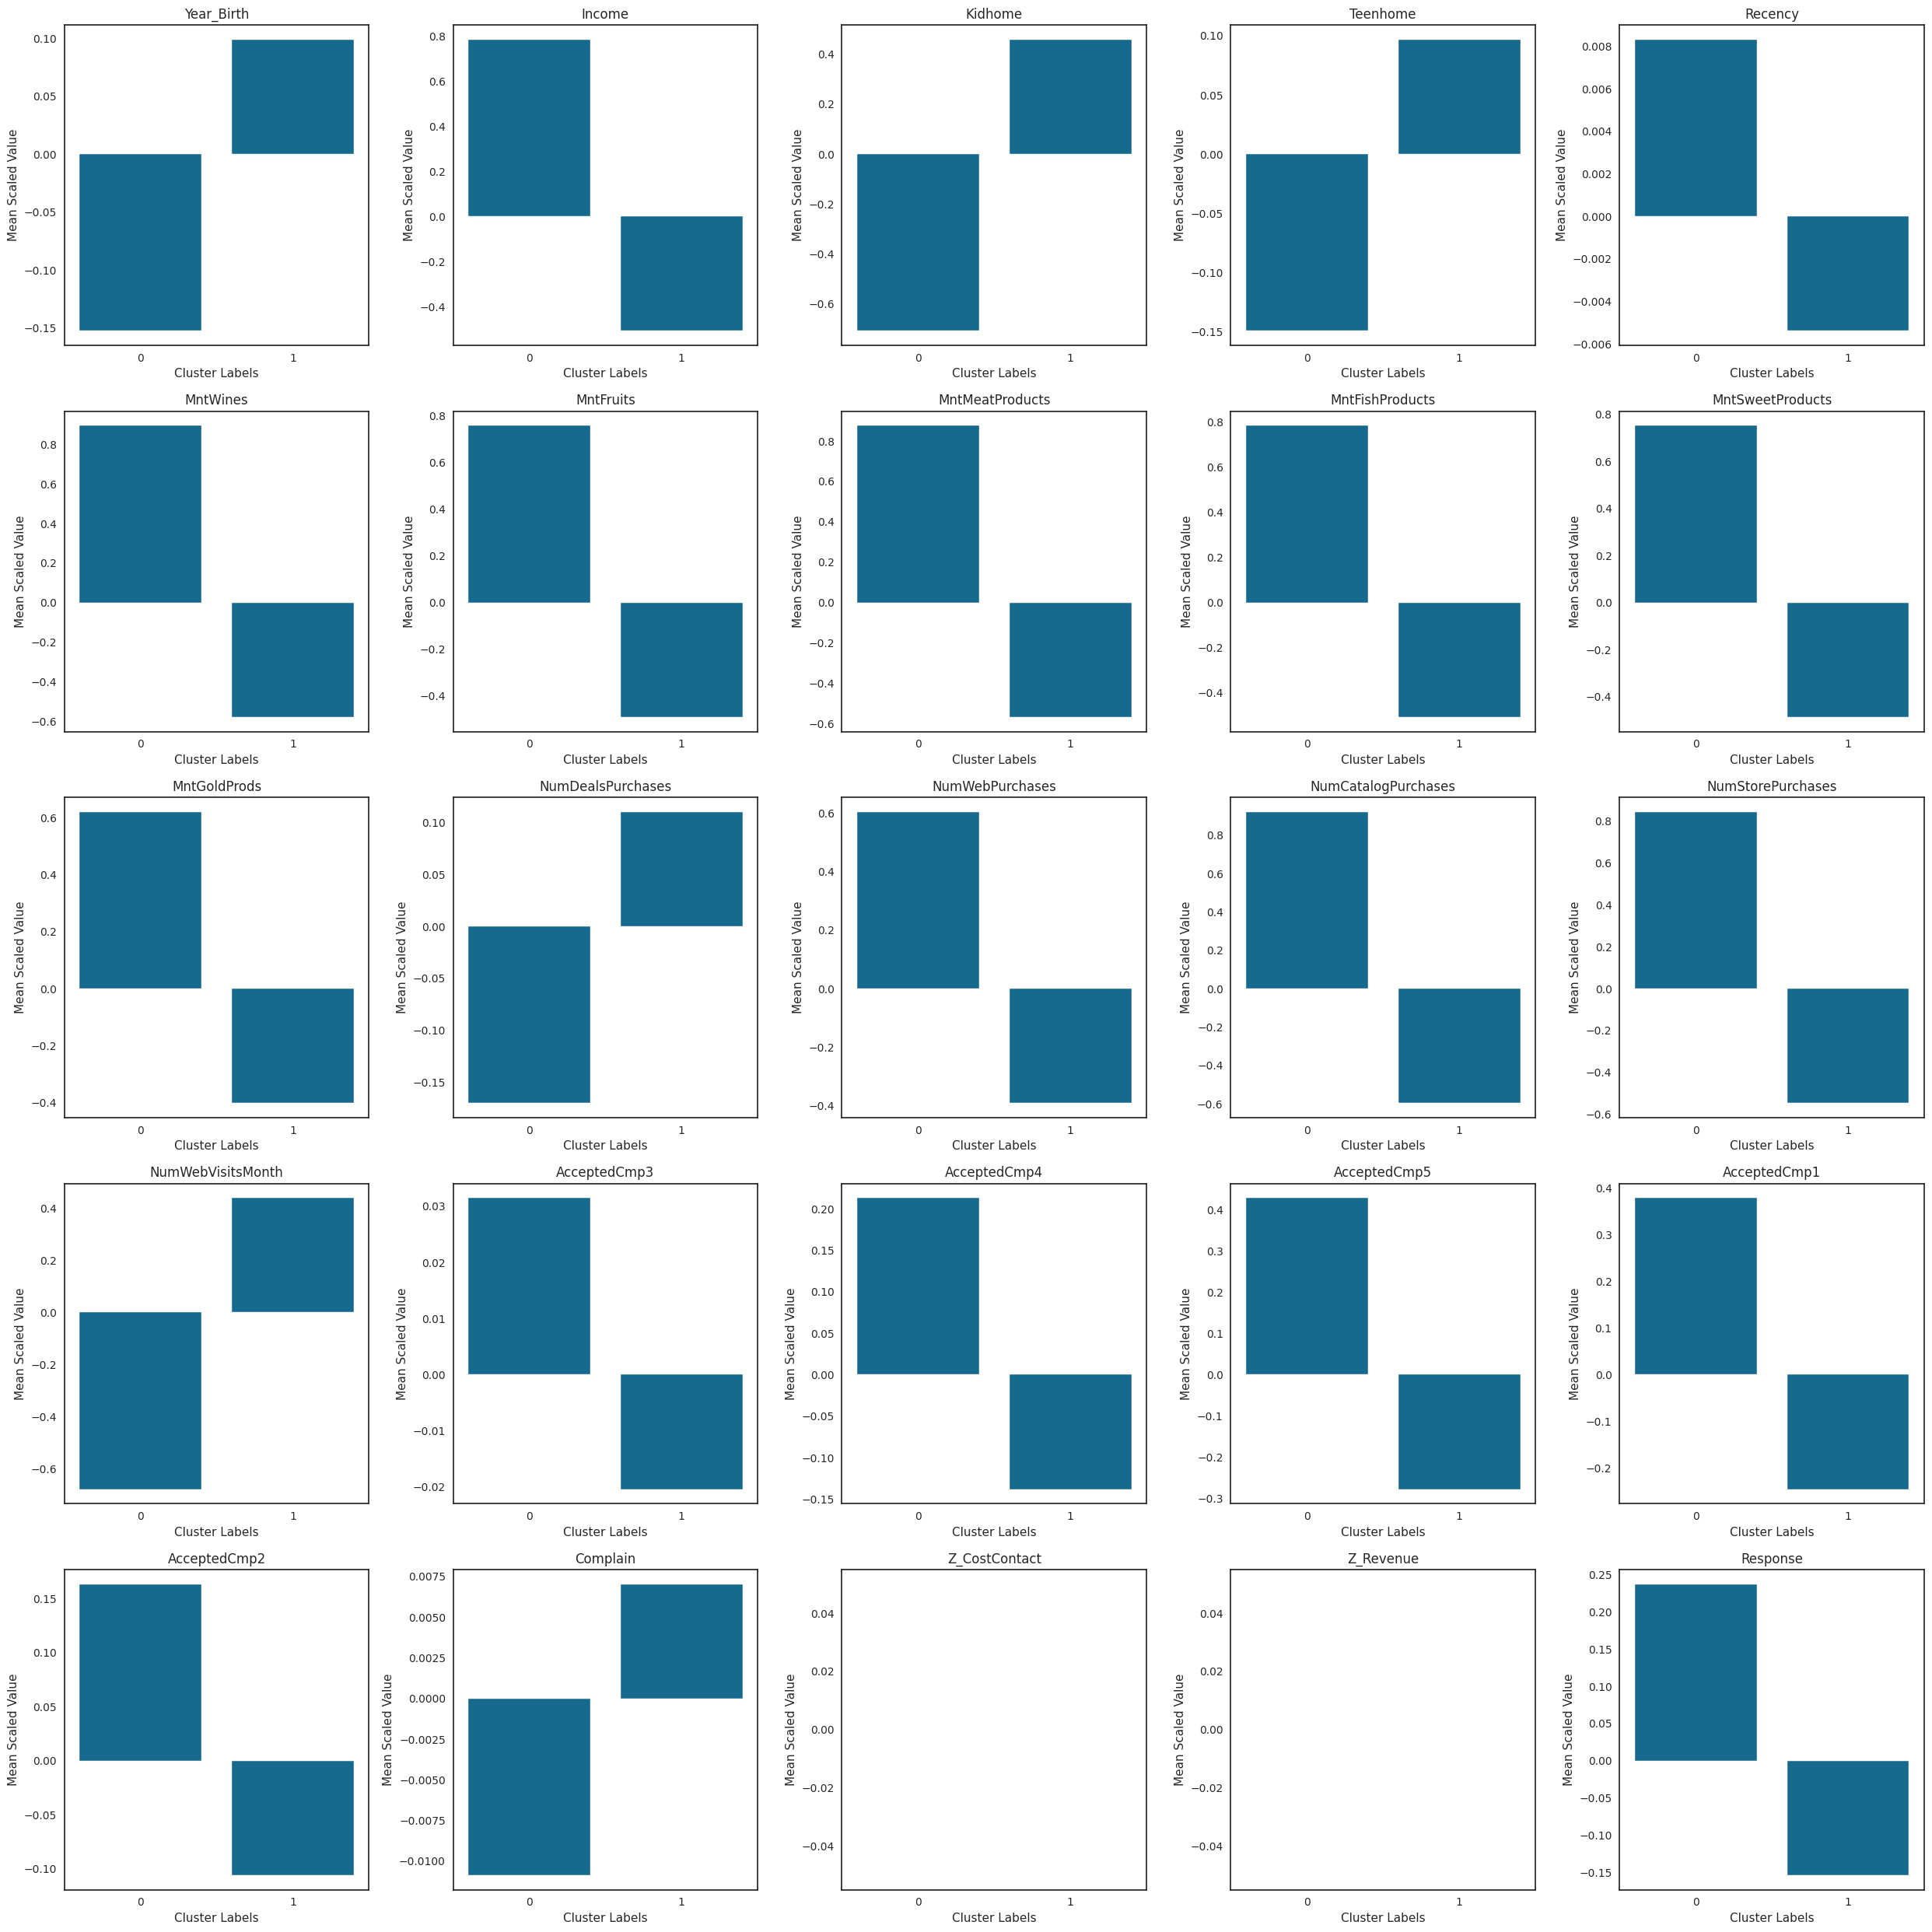

In [ ]:
mean_per_label = data_scaled_copy.groupby('Labels').mean()

# Calculate the number of rows and columns for the subplot grid
num_features = len(mean_per_label.columns)
rows = 5
cols = 5

fig, axes = plt.subplots(nrows=rows, ncols=cols, figsize=(25,25))
axes = axes.flatten()

for i, col in enumerate(mean_per_label.columns):
    sns.barplot(x=mean_per_label.index, y=mean_per_label[col], ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_ylabel('Mean Scaled Value')
    axes[i].set_xlabel('Cluster Labels')

plt.tight_layout()
plt.show()

##### **Observations:**


*   Group 0 customers are younger and have fewer or no children (kids and teens) and also have higher income. This group makes the most purchases online, through catalogs, and instore. This group spends the most amount on products in all categories (meats, fish, wine, sweets, fruits, and gold)

*   Group 0 customers make less purchases with deals and visit the company's website less per month compared to Group 1.

*   Group 0 customers responded more positively to the 1st and 5th campaigns. They were half as responsive to the 2nd and 4th campaigns. The 3rd Campaign was the least effective on them.

*   Group 0 responsed to the last campain positively, thought that campain wasn't as successful as the 1st and 5th campaigns.

*   Group 1 customers are older than group 0, have lower income, and have more children (kids and teens) per household.
*   Group 1 customers make more deal purchases and visit the company's website more frequently.


*   Group 1 customers are less responsive to compaigns in general than group 0

*   Group 1 complains more than group 0, though complaints don't appear to be many across groups.









## **Business Recommedations**

#### **Question 12**: Based on the cluster insights, what business recommendations can be provided?



1.   It appears that customer's annual household income largely determines how much the customer spends on any products sold by the company. It is likely that customers in group 0 will be willing to pay for pricy and luxury products across categories. However, group 1 customers may require access to more affordable products in any of the categories.

2.   The 1st and 5th campaigns were most effective for the higher earning customers of group 0. The company should continue to make similar campaigns. New campaign strategies that are geared towards increasing spending for the customers in group 1 are necessary.

1.   The group 1 customers pay more frequent visits to the company's website, and the company can leverage this traffic by publishing their campaigns online. Since the same group tends to make more purchases with deals, deals can be made more available for online sales where customers in group 1 will easily see them.

2.   Group 1 customers have more kids and teens in their households and are likely to buy products for them. More campaigns, products, and deals for  products  for kids and teens could help retain these customers and increase their spending with the company.



